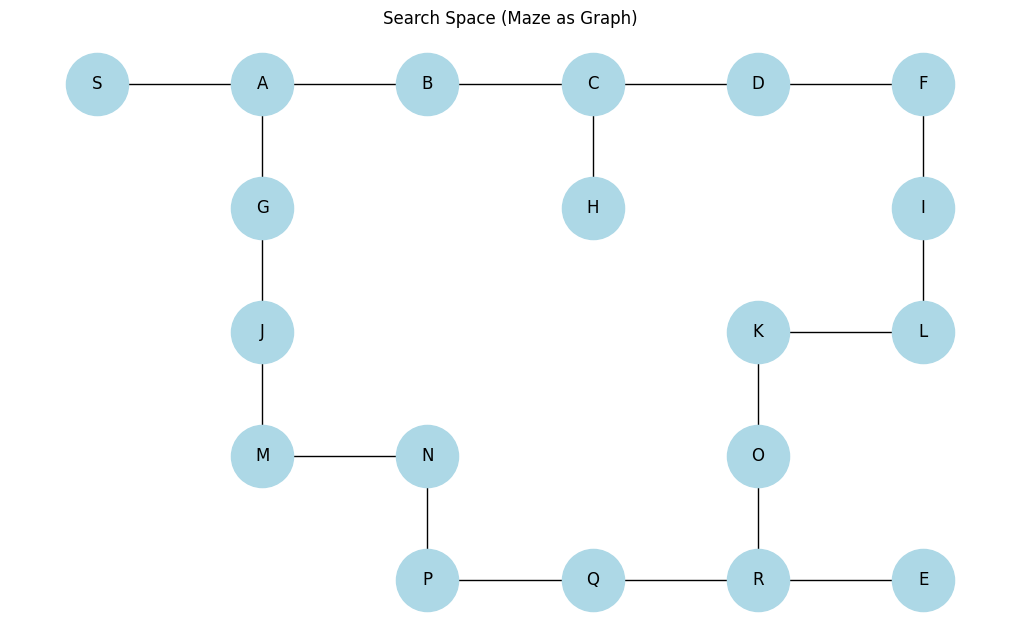

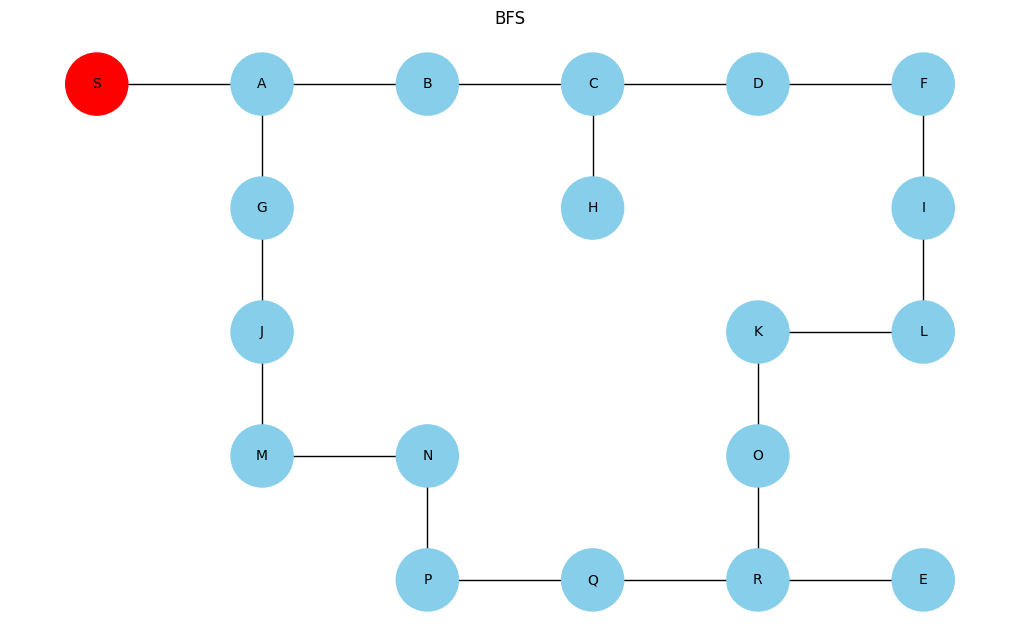

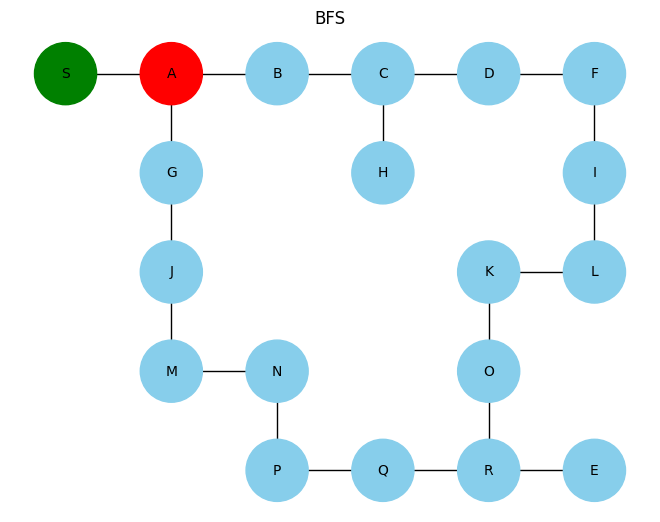

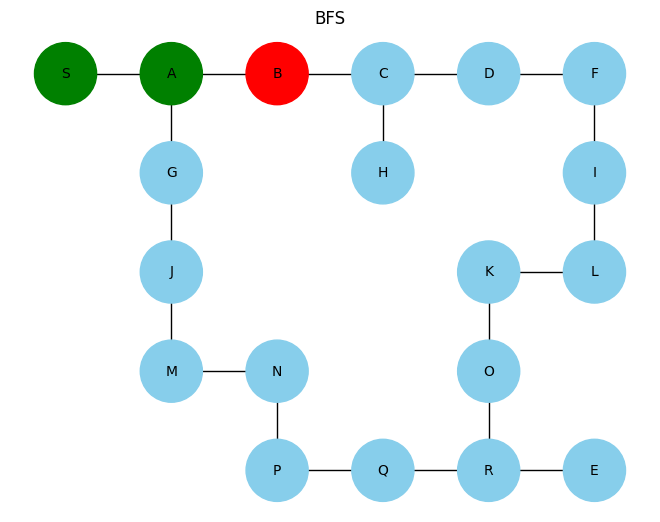

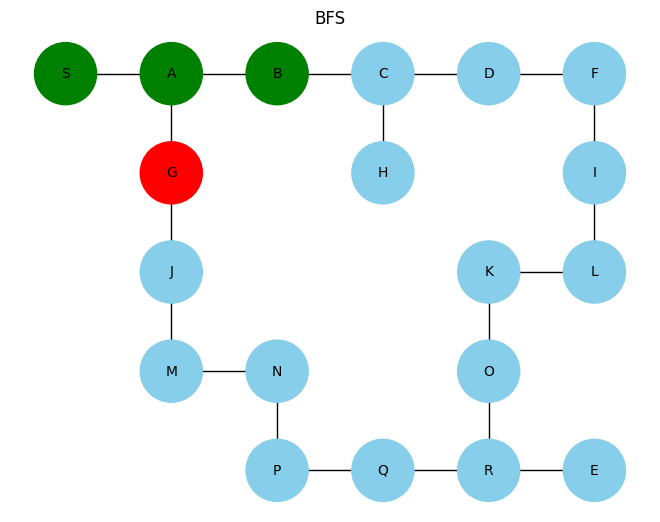

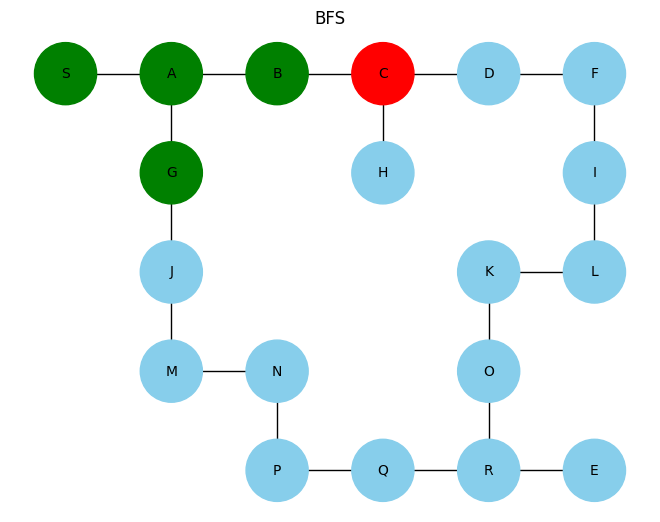

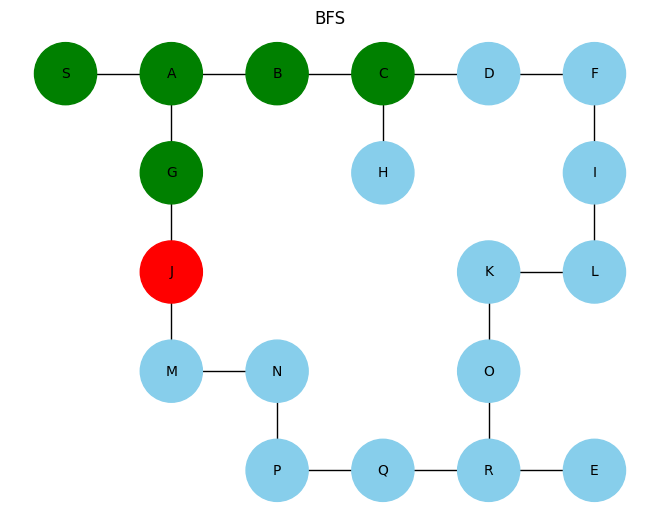

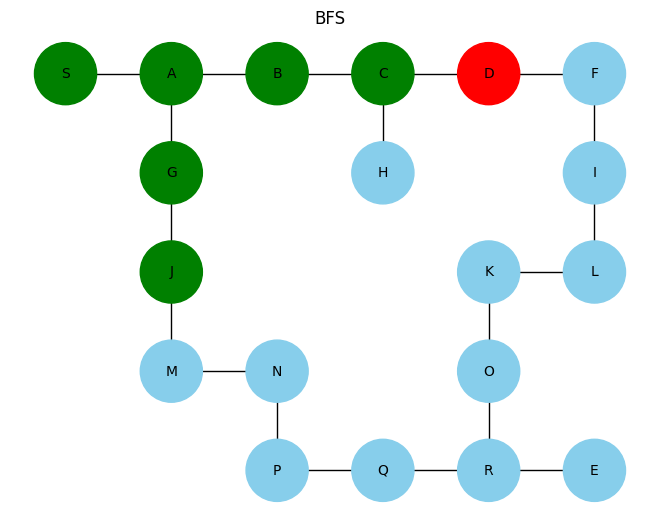

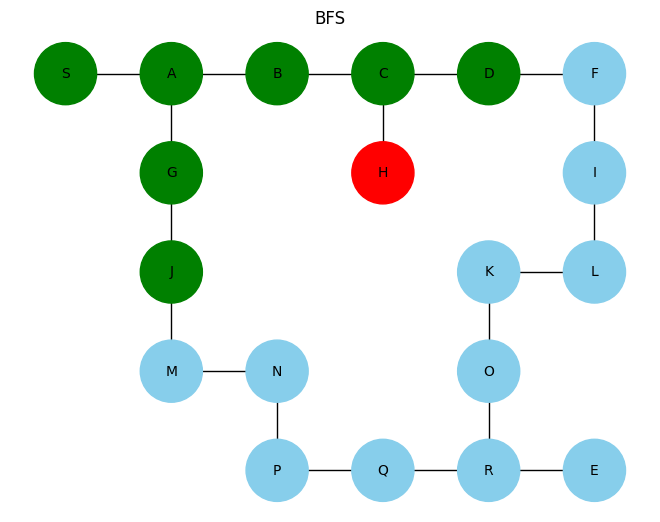

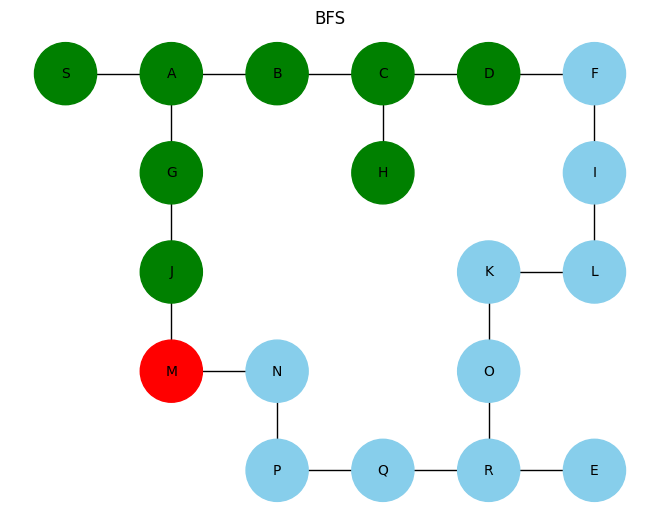

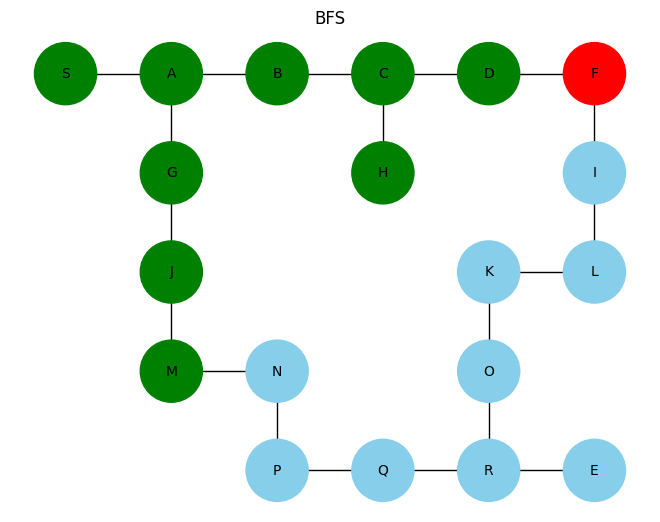

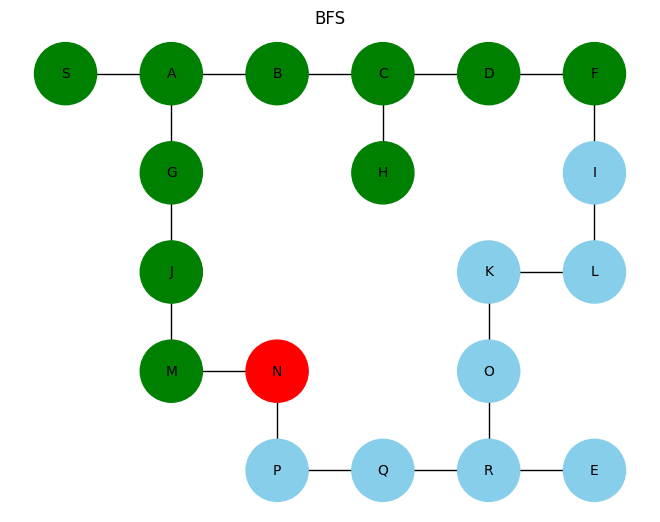

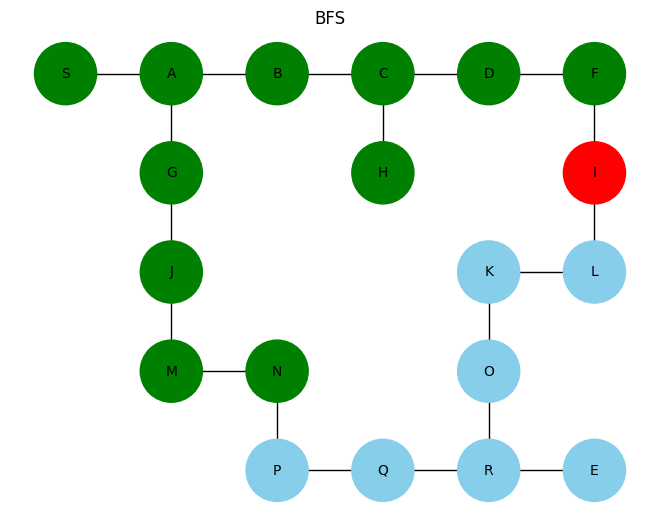

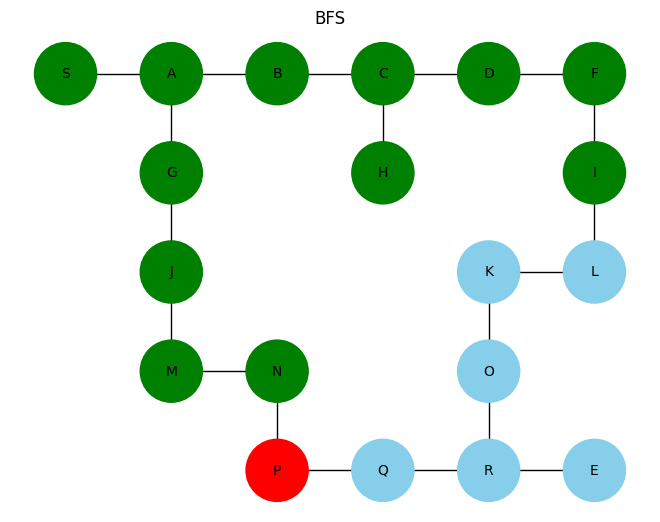

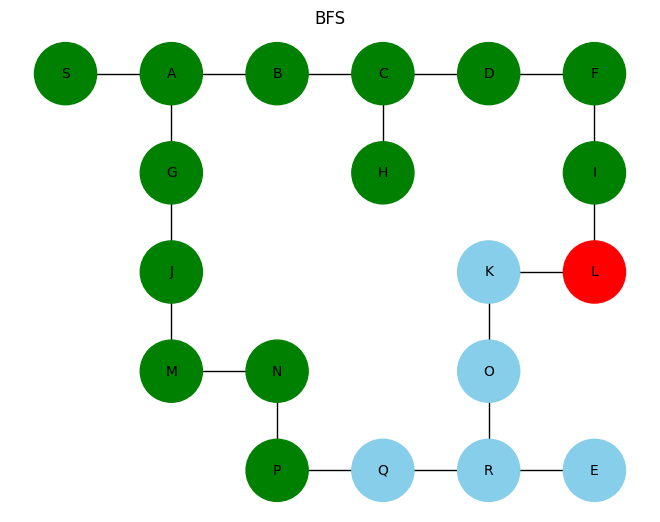

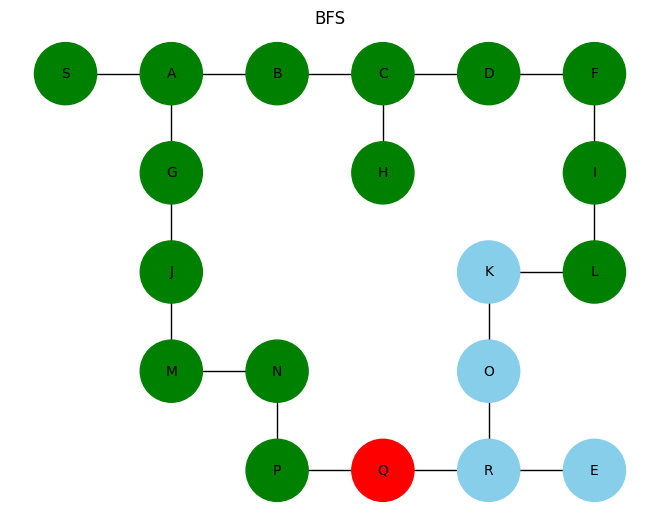

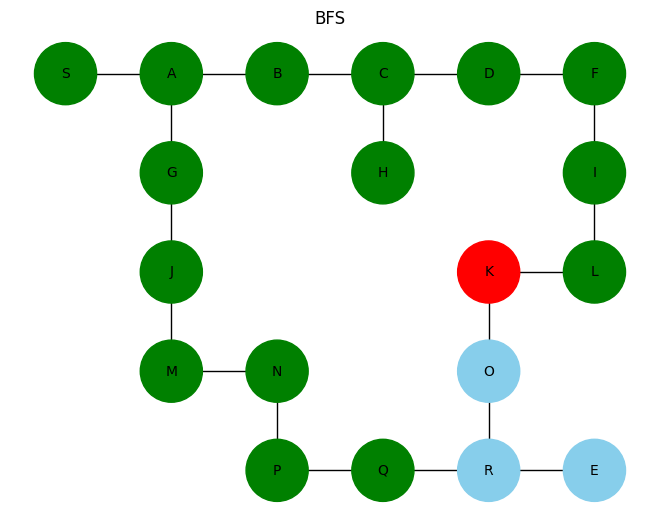

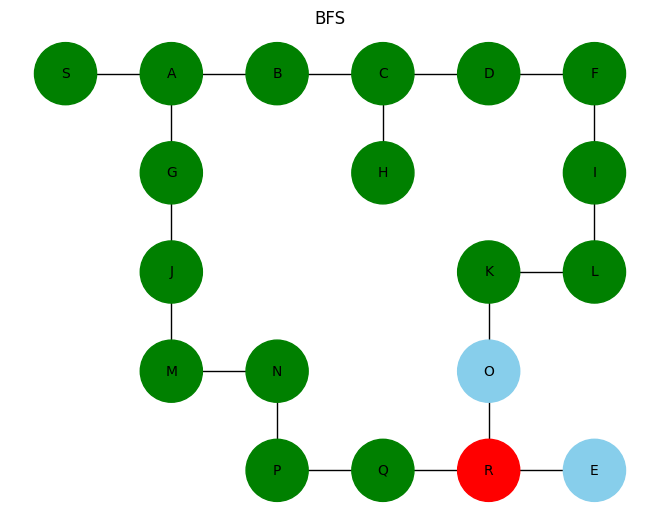

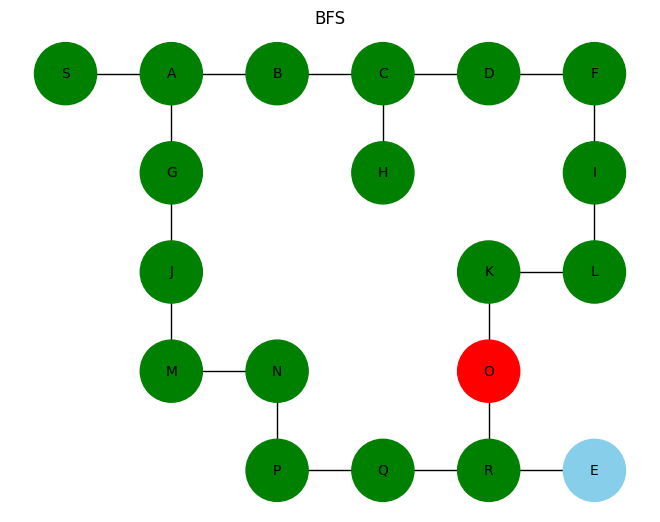

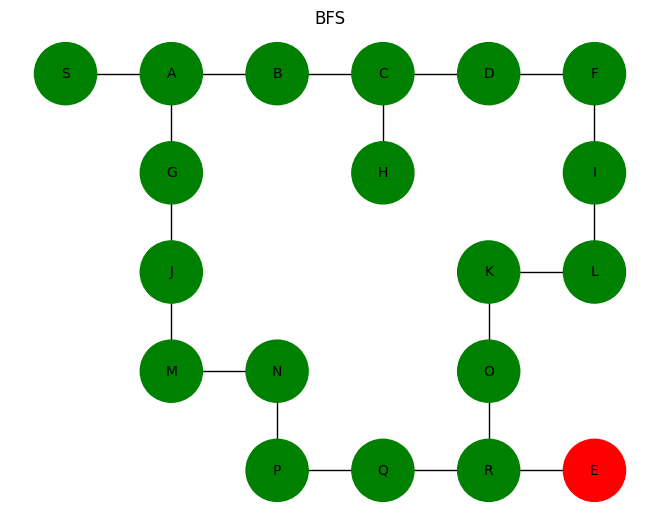

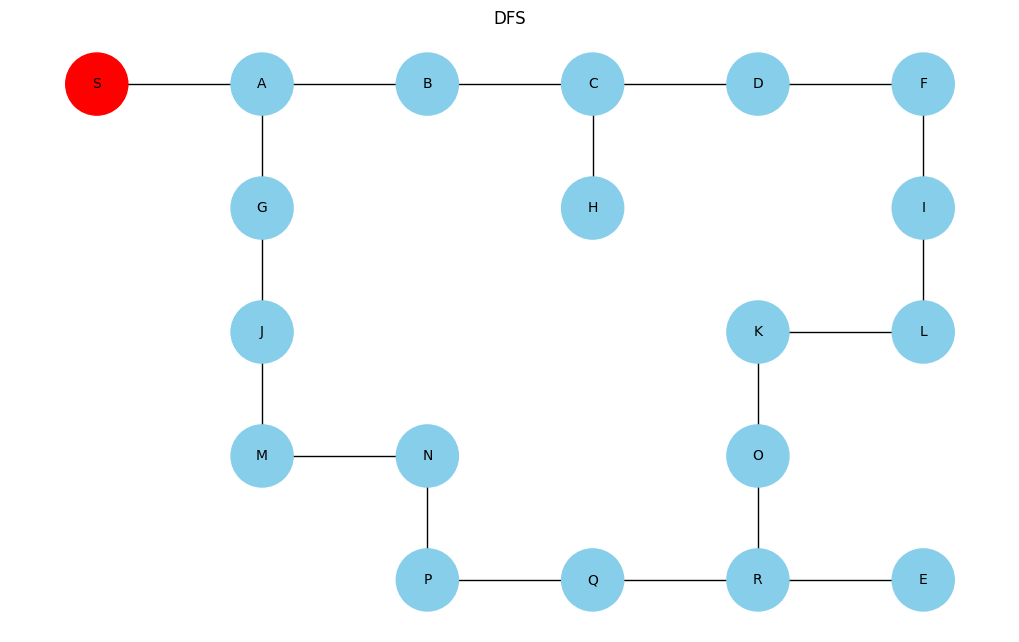

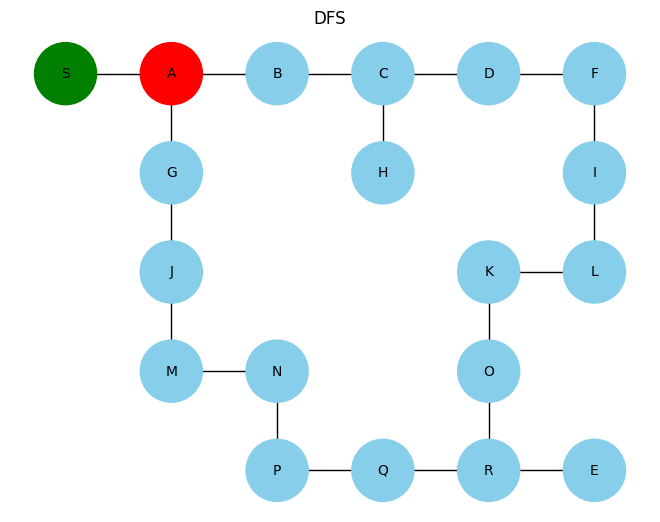

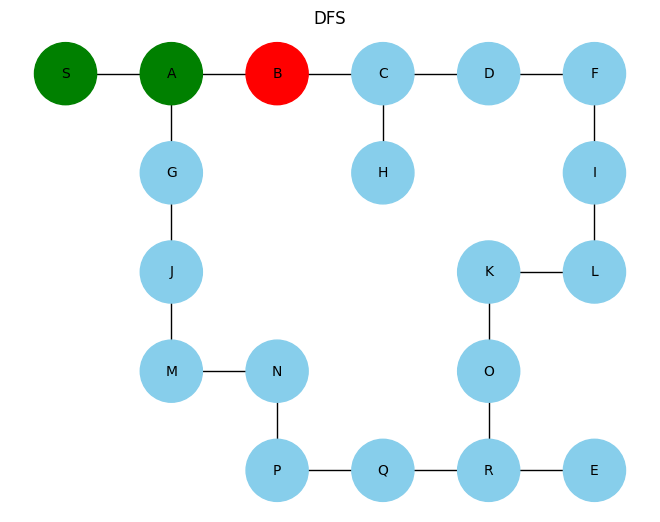

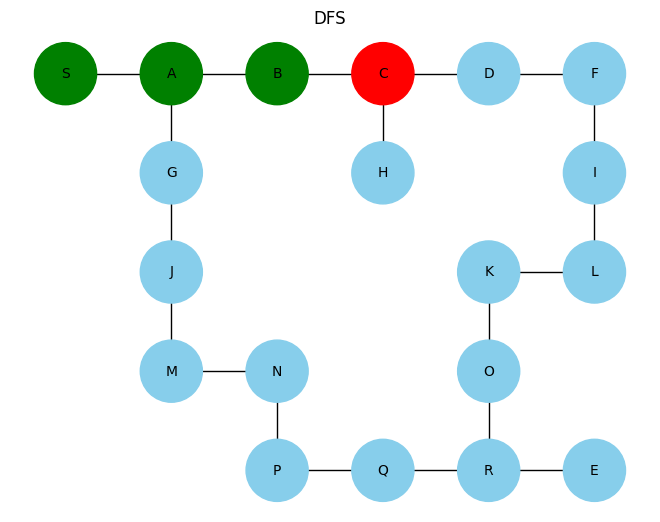

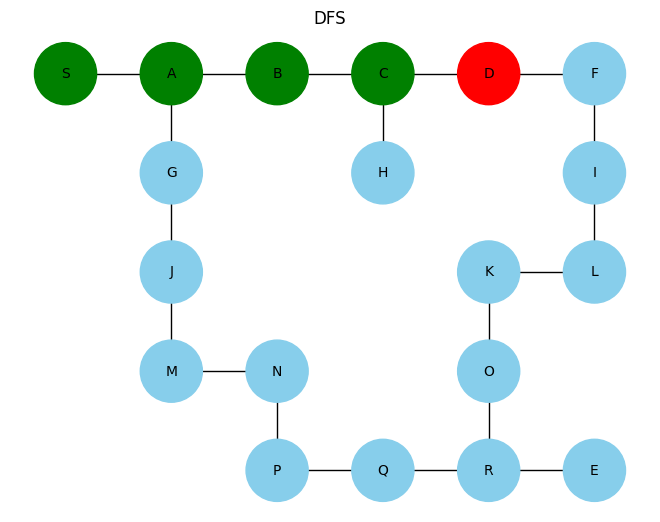

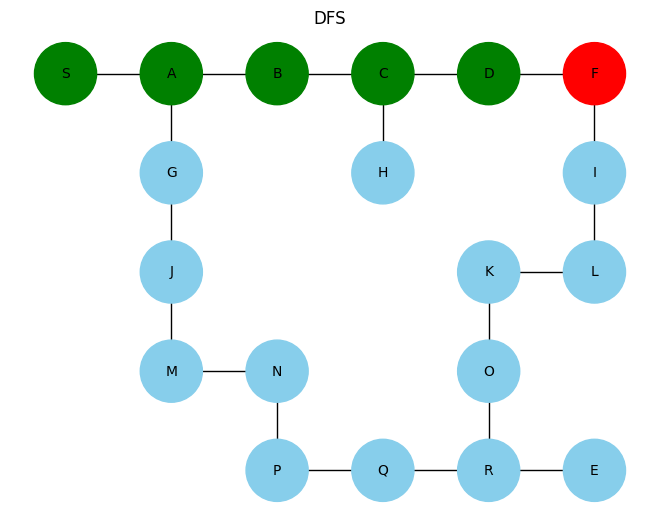

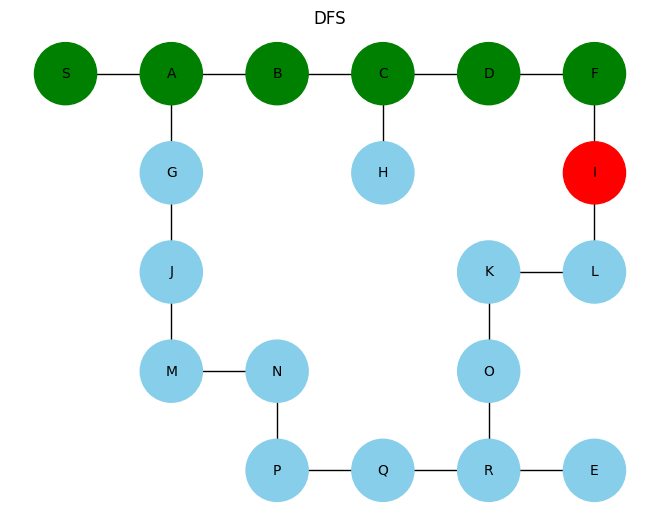

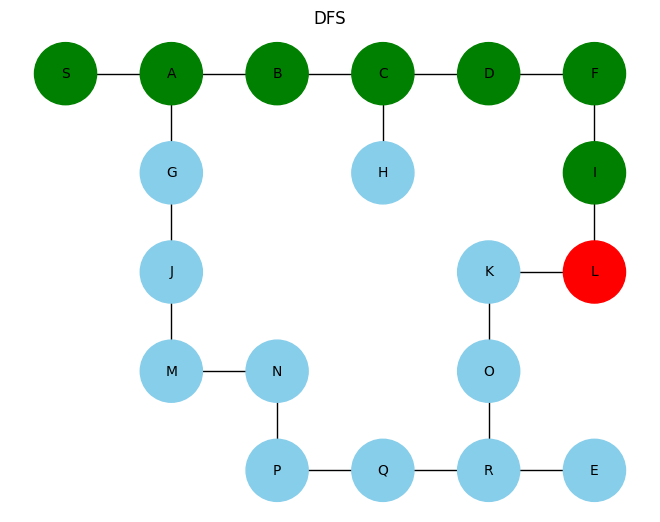

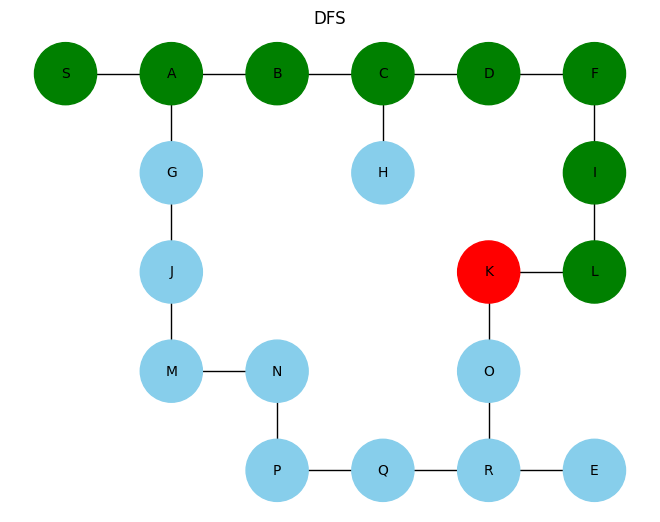

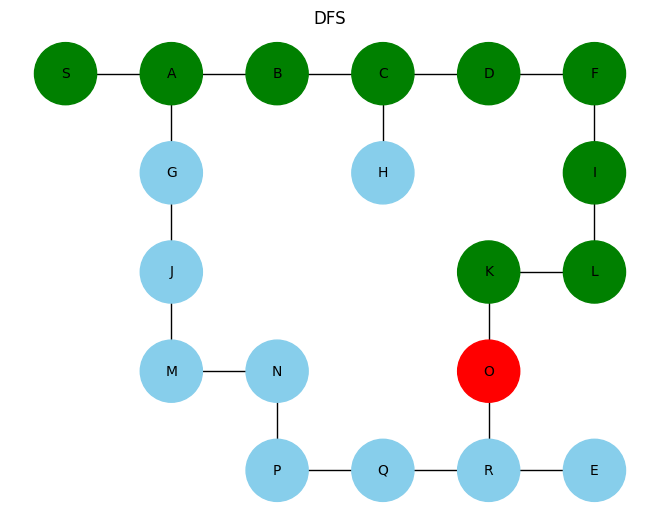

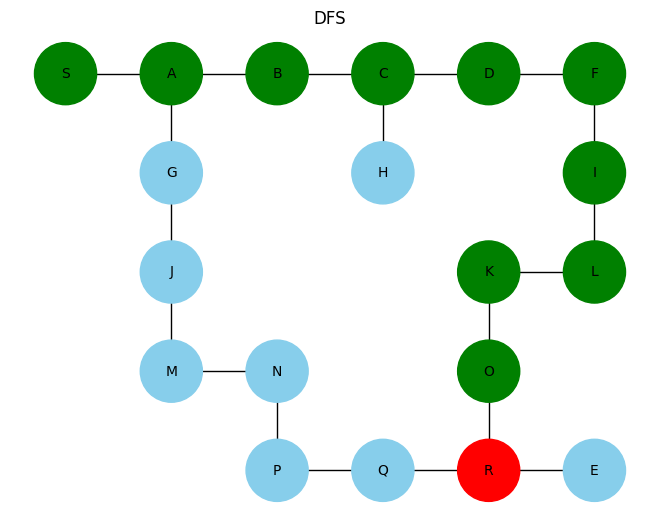

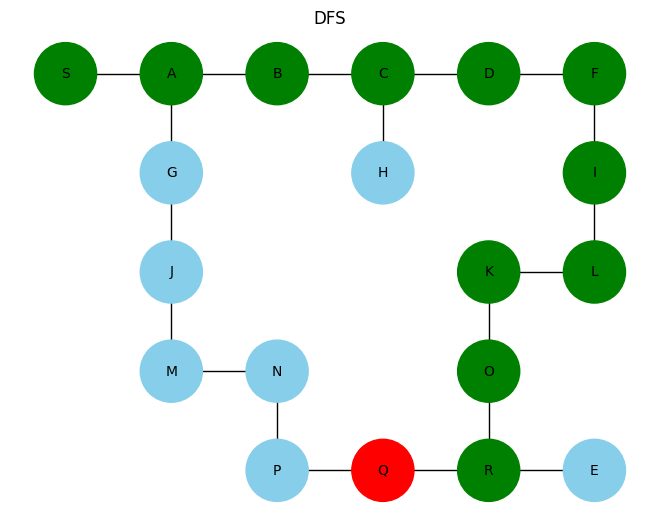

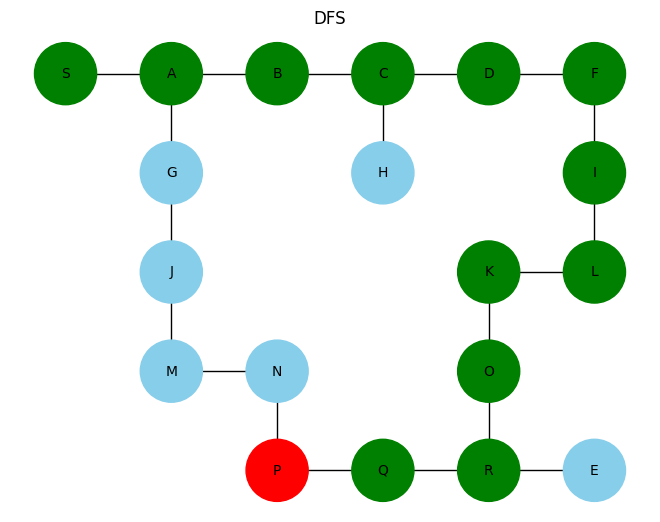

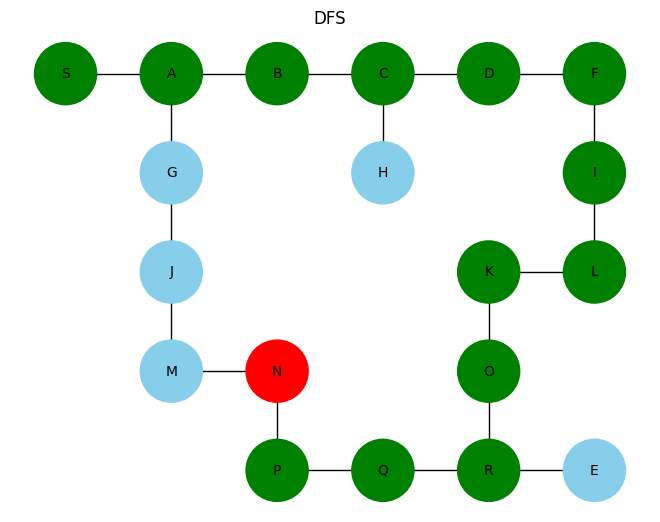

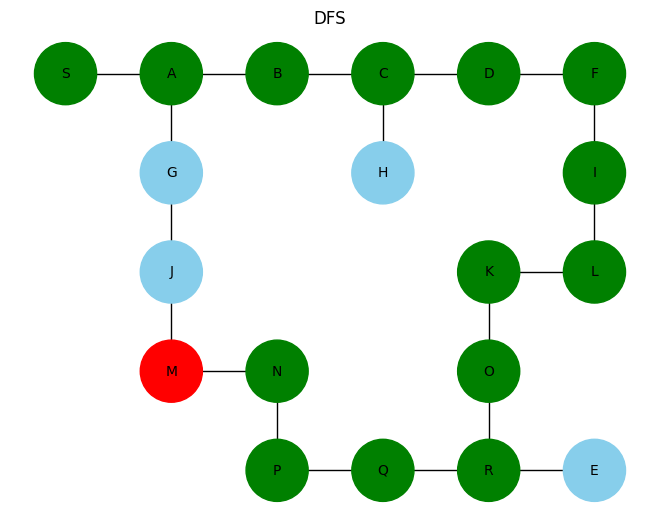

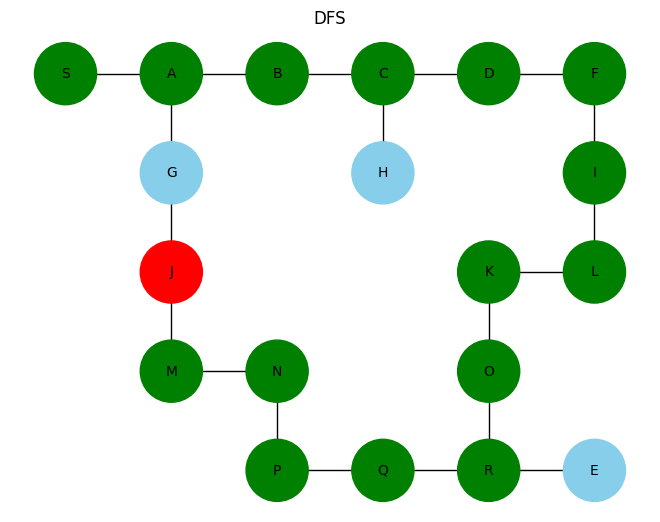

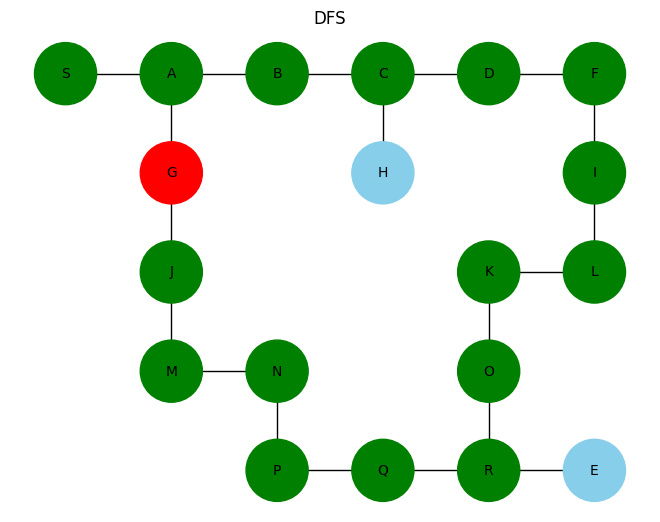

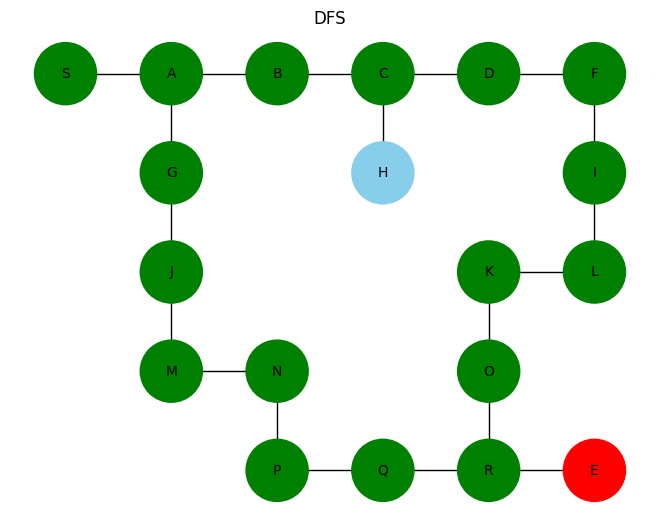

In [ ]:
!pip install networkx matplotlib

import networkx as nx
import matplotlib.pyplot as plt
from collections import deque

# -----------------------------------
# MATRIX
# -----------------------------------
maze = [
['S','A','B','C','D','F'],
['#','G','#','H','#','I'],
['#','J','#','#','K','L'],
['#','M','N','#','O','#'],
['#','#','P','Q','R','E']
]

rows = len(maze)
cols = len(maze[0])

# -----------------------------------
# BUILD GRAPH
# -----------------------------------
G = nx.Graph()
pos = {}
labels = {}

for r in range(rows):
    for c in range(cols):
        if maze[r][c] != '#':
            pos[(r,c)] = (c, -r)   # GRID POSITION (PERFECT ALIGNMENT)
            labels[(r,c)] = maze[r][c]

            for dr, dc in [(0,1),(1,0),(0,-1),(-1,0)]:
                nr, nc = r+dr, c+dc
                if 0 <= nr < rows and 0 <= nc < cols:
                    if maze[nr][nc] != '#':
                        G.add_edge((r,c),(nr,nc))

# find start and goal
start = [k for k,v in labels.items() if v=='S'][0]
goal  = [k for k,v in labels.items() if v=='E'][0]

# -----------------------------------
# DRAW FUNCTION
# -----------------------------------
def draw(title, visited=set(), current=None):
    plt.clf()

    colors = []
    for node in G.nodes():
        if node == current:
            colors.append("red")
        elif node in visited:
            colors.append("green")
        else:
            colors.append("skyblue")

    nx.draw(G, pos, labels=labels,
            node_color=colors,
            node_size=2000,
            font_size=10)

    plt.title(title)
    plt.pause(0.8)

# -----------------------------------
# SHOW SEARCH SPACE
# -----------------------------------
def show_tree():
    plt.figure(figsize=(10,6))
    nx.draw(G, pos, labels=labels,
            node_color="lightblue",
            node_size=2000)
    plt.title("Search Space (Maze as Graph)")
    plt.show()

# -----------------------------------
# BFS
# -----------------------------------
def bfs():
    visited = set()
    queue = deque([start])

    plt.figure(figsize=(10,6))

    while queue:
        node = queue.popleft()

        if node not in visited:
            visited.add(node)

            draw("BFS", visited, node)

            if node == goal:
                break

            for n in G[node]:
                if n not in visited:
                    queue.append(n)

    plt.show()

# -----------------------------------
# DFS
# -----------------------------------
def dfs():
    visited = set()
    stack = [start]

    plt.figure(figsize=(10,6))

    while stack:
        node = stack.pop()

        if node not in visited:
            visited.add(node)

            draw("DFS", visited, node)

            if node == goal:
                break

            for n in reversed(list(G[node])):
                if n not in visited:
                    stack.append(n)

    plt.show()

# -----------------------------------
# RUN
# -----------------------------------
show_tree()
bfs()
dfs()

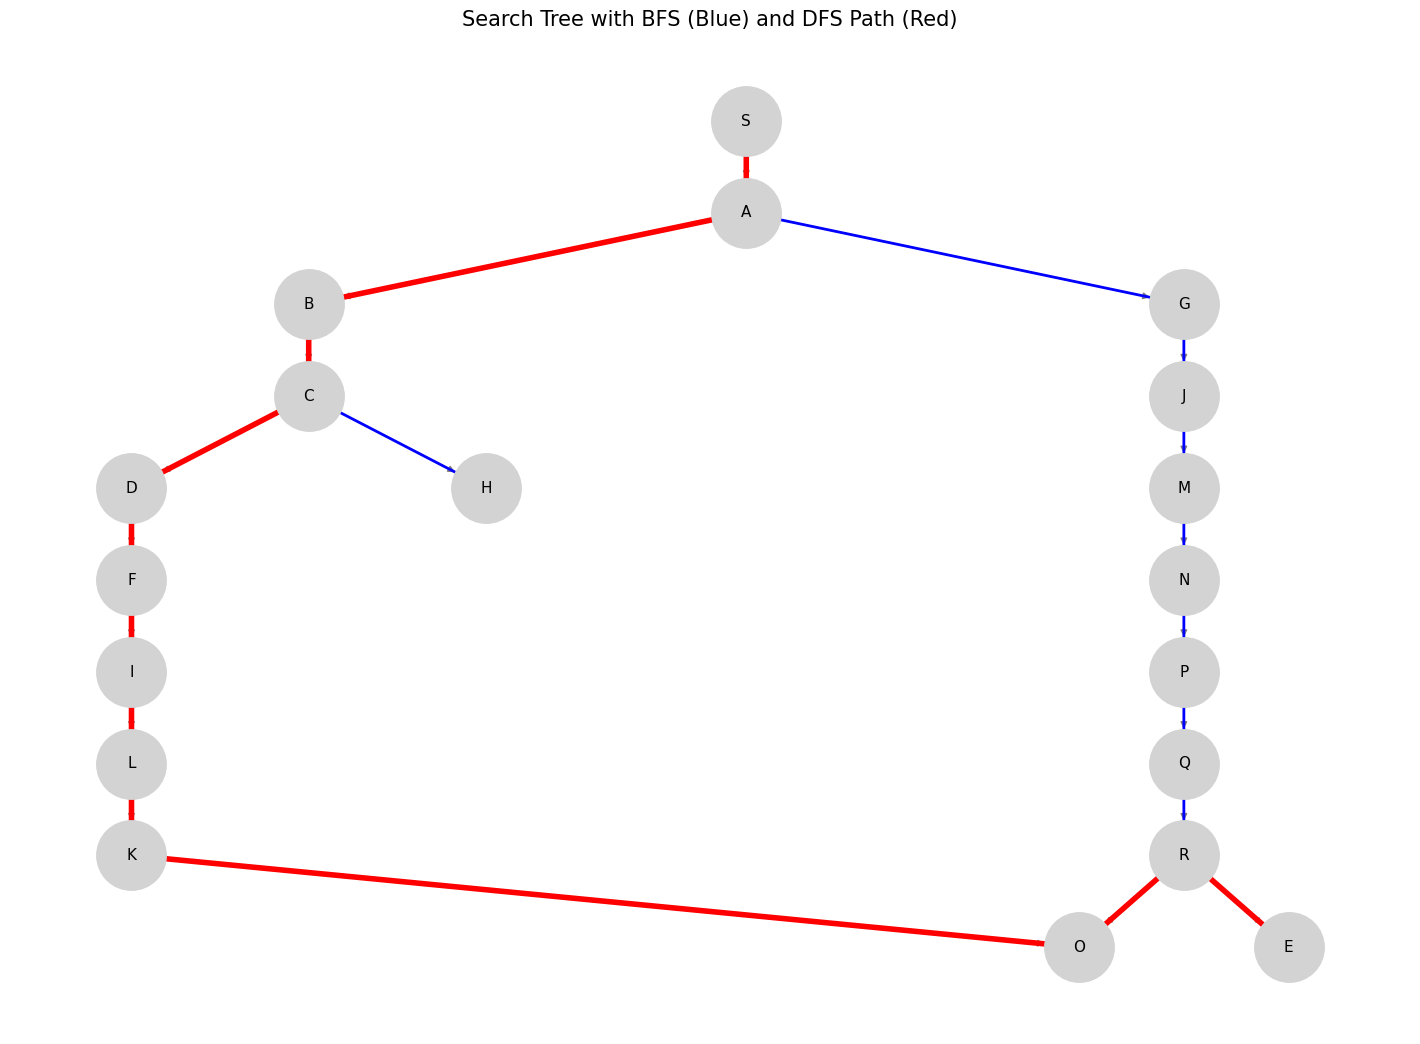

In [ ]:
# Install once
!pip install networkx matplotlib

import networkx as nx
import matplotlib.pyplot as plt
from collections import deque

# -----------------------------------
# MATRIX
# -----------------------------------
maze = [
['S','A','B','C','D','F'],
['#','G','#','H','#','I'],
['#','J','#','#','K','L'],
['#','M','N','#','O','#'],
['#','#','P','Q','R','E']
]

rows = len(maze)
cols = len(maze[0])

# -----------------------------------
# BUILD GRAPH
# -----------------------------------
G = nx.Graph()
labels = {}

for r in range(rows):
    for c in range(cols):
        if maze[r][c] != '#':
            labels[(r,c)] = maze[r][c]

            for dr, dc in [(0,1),(1,0),(0,-1),(-1,0)]:
                nr, nc = r+dr, c+dc
                if 0 <= nr < rows and 0 <= nc < cols:
                    if maze[nr][nc] != '#':
                        G.add_edge((r,c),(nr,nc))

# find start & goal
start = [k for k,v in labels.items() if v=='S'][0]
goal  = [k for k,v in labels.items() if v=='E'][0]

# -----------------------------------
# BUILD BFS TREE
# -----------------------------------
def build_bfs_tree(G, start):
    tree = nx.DiGraph()
    visited = set()
    queue = deque([start])

    while queue:
        node = queue.popleft()
        if node not in visited:
            visited.add(node)

            for neighbor in G[node]:
                if neighbor not in visited:
                    tree.add_edge(node, neighbor)
                    queue.append(neighbor)

    return tree

tree = build_bfs_tree(G, start)

# -----------------------------------
# DFS PATH (ONLY FINAL PATH)
# -----------------------------------
def dfs_path(G, start, goal):
    stack = [(start, [start])]
    visited = set()

    while stack:
        node, path = stack.pop()

        if node == goal:
            return path

        if node not in visited:
            visited.add(node)

            for n in reversed(list(G[node])):
                stack.append((n, path + [n]))

    return []

dfs_path_nodes = dfs_path(G, start, goal)

# convert path to edges
dfs_edges = [(dfs_path_nodes[i], dfs_path_nodes[i+1])
             for i in range(len(dfs_path_nodes)-1)]

# -----------------------------------
# HIERARCHY LAYOUT
# -----------------------------------
def hierarchy_pos(G, root, width=2.0, vert_gap=0.7, vert_loc=0, xcenter=0.5, pos=None):
    if pos is None:
        pos = {root:(xcenter, vert_loc)}
    else:
        pos[root] = (xcenter, vert_loc)

    children = list(G.successors(root))
    if children:
        dx = width / len(children)
        nextx = xcenter - width/2 + dx/2

        for child in children:
            pos = hierarchy_pos(G, child,
                                width=dx*0.9,
                                vert_gap=vert_gap,
                                vert_loc=vert_loc-vert_gap,
                                xcenter=nextx,
                                pos=pos)
            nextx += dx
    return pos

pos = hierarchy_pos(tree, start)

# -----------------------------------
# DRAW TREE WITH HIGHLIGHTS
# -----------------------------------
plt.figure(figsize=(14,10))

tree_labels = {node: labels[node] for node in tree.nodes()}

# Draw base tree
nx.draw(tree, pos,
        labels=tree_labels,
        node_color="lightgray",
        node_size=2500,
        font_size=11,
        edge_color="gray",
        arrows=True)

# 🔵 Highlight BFS tree edges
nx.draw_networkx_edges(
    tree, pos,
    edgelist=list(tree.edges()),
    edge_color="blue",
    width=2
)

# 🔴 Highlight DFS path
nx.draw_networkx_edges(
    tree, pos,
    edgelist=dfs_edges,
    edge_color="red",
    width=4
)

plt.title("Search Tree with BFS (Blue) and DFS Path (Red)", fontsize=15)
plt.show()